<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [VGI Container Registry Worker](https://github.com/Query-farm/vgi-software-packages)

Discover Docker Hub, Quay, GHCR and GitLab containers and inspect OCI metadata.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-software-packages/blob/main/notebooks/04_a_tag_page_is_not_an_image_identity.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-software-packages/blob/main/notebooks/README.md)


## 04 · A tag page is not an image identity

A repository search finds names, and a bounded tag page returns labels. Neither is
an immutable image identity. Inspect the configured Quay contract, retain missing
provider measures, and resolve a deliberately chosen tag alongside a previously pinned
digest. This links discovery to notebook 02 without downloading any image layer payload.

### Bound the tag inventory

Use **TAG_LIMIT = 8**, then try **16**. The search remains bounded at eight results and
the selected repository/tag/digest remain fixed. Increasing this limit requests more tag
labels; it is not a newest-version rule, security filter or image selection. Provider
ordering and live contents can change between runs.

In [1]:
TAG_LIMIT = 8  # Experiment: 16; integer range 4–32

### Run independently

Read the saved results on GitHub or choose **Open in Colab** and Run All. The base
install preserves compatible preloaded plotting/kernel packages; local publication uses
the optional `[runner]` extra. Package/extension/native-worker downloads and these live
public metadata requests require internet. No checkout, Bun build, package installation
or container runtime is required. Hosted Colab is not tested; fresh preloaded Python 3.12
notebook-only execution checks each of the two native launcher paths. See [setup and
provenance](README.md).

In [2]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.44":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.44"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.44":
    raise RuntimeError("Install shared tools 0.3.44, restart, and Run All.")

In [3]:
import json
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from vgi_notebooks import prepare
from vgi_notebooks.presentation import finish, prose, theme
from vgi_notebooks.session import connect

prepare("software-packages")
from public_sources import PublicSources

%matplotlib inline
theme()
STARTED_UTC = datetime.now(UTC).isoformat(timespec="seconds")
public = PublicSources()
session = connect(globals())
connection = session.connection
assert connection.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
assert connection.execute("SELECT current_setting('TimeZone')").fetchone()[0] == "UTC"
Path("artifacts").mkdir(exist_ok=True)

if type(TAG_LIMIT) is not int or not 4 <= TAG_LIMIT <= 32:
    raise ValueError("TAG_LIMIT must be an integer from 4 through 32")

### Anonymous public reads with an empty credential store

The helper supplies only anonymous public PyPI, npm and Quay endpoints and an empty
disposable metadata cache. Shared setup opens an empty temporary SQL-secret directory,
disables persistence and JupySQL default-INI autoload, and fixes UTC for all SQL cursors.
No saved secrets are read and no SQL credentials are created. Cleanup closes the session
and removes temporary configuration/cache state, restoring inherited settings.

These are **live public metadata reads**, with no recording or fallback. Retrieval time
is not publication time. Missing provider fields remain NULL; metadata sizes and hashes
do not establish package installation, layer-payload integrity or runtime behavior.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'containers' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-software-packages@v0.2.0/vgi-containers-worker');

,Success


### Establish the source and keep query populations separate

Join the three reference tables by source ID. Native readiness means the adapter can
perform a search; it is not a live availability guarantee. Its NULL index completeness
does not mean the whole registry has been inventoried. The package-worker entrypoint
has a different catalog; these tables describe only the container source.

Search for `prometheus`, then inspect the explicitly named `prometheus/prometheus`
repository. Search scores belong to this provider and query; absent star/pull/official
fields remain NULL. The repository description is metadata, not an executed program or
a trusted instruction. We display its character count rather than render its embedded
markup. A search result count and a tag count describe different populations.

In [5]:
%%sql
CREATE TABLE sources AS SELECT * FROM containers.main.sources;
CREATE TABLE capabilities AS SELECT * FROM containers.main.capabilities;
CREATE TABLE source_status AS SELECT * FROM containers.main.source_status;
CREATE TABLE discovered AS SELECT * FROM containers.main.search('quay_public','prometheus',8);
CREATE TABLE repository AS SELECT * FROM containers.main.repository('quay_public','prometheus/prometheus',max_results:=1000);
CREATE TABLE tag_page AS SELECT * FROM containers.main.tags('quay_public','prometheus/prometheus',max_results:={{TAG_LIMIT}});
SELECT s.source_id,s.endpoint,s.authentication,s.search_mode,st.ready,st.complete,
 count(*) FILTER(WHERE c.supported) AS supported_operations
FROM sources s JOIN capabilities c USING(source_id) JOIN source_status st USING(source_id)
GROUP BY ALL;
SELECT name,score,stars,pulls,official,observed_at FROM discovered ORDER BY name;
SELECT name,length(description) AS description_characters,stars,pulls,observed_at FROM repository;
SELECT tag,observed_at FROM tag_page ORDER BY tag;
SELECT count(*) AS tag_rows,{{TAG_LIMIT}} AS requested_limit,count(*)={{TAG_LIMIT}} AS reached_limit,
 count(*) FILTER(WHERE tag='v3.2.1') AS chosen_tag_in_this_page FROM tag_page;

,tag_rows,requested_limit,reached_limit,chosen_tag_in_this_page
0,8,8,True,0


In [6]:
%%sql inventory <<
SELECT 'Search results' AS population,count(*) AS returned_rows,8 AS row_budget FROM discovered
UNION ALL SELECT 'Tag labels',count(*),{{TAG_LIMIT}} FROM tag_page;

In [7]:
display(inventory)
tags = connection.execute("SELECT tag FROM tag_page ORDER BY tag").df()
search_names = connection.execute("SELECT name FROM discovered ORDER BY name").df()
present = bool((tags.tag == "v3.2.1").any())
prose(
    f"The search returns **{len(search_names)} names** and the tag request returns **{len(tags)} labels** with a budget of **{TAG_LIMIT}**. The deliberately chosen tag `v3.2.1` is **{'present' if present else 'absent'} in this bounded tag page**. Absence from this page does not establish that the tag is absent from the repository; the next query resolves it directly. No lexical sorting is used to choose a newest release."
)

,population,returned_rows,row_budget
0,Search results,8,8
1,Tag labels,8,8


The search returns **8 names** and the tag request returns **8 labels** with a budget of **8**. The deliberately chosen tag `v3.2.1` is **absent in this bounded tag page**. Absence from this page does not establish that the tag is absent from the repository; the next query resolves it directly. No lexical sorting is used to choose a newest release.

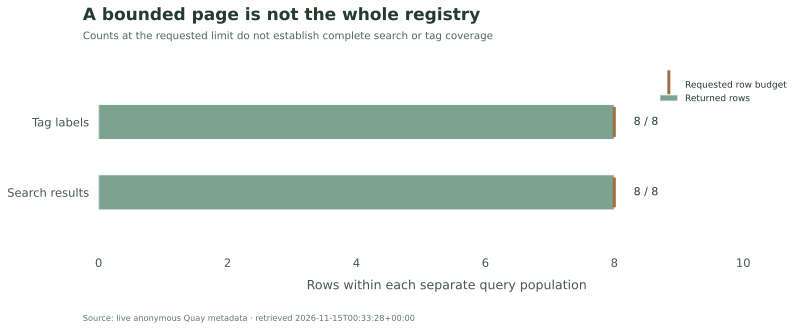

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.8))
y = np.arange(len(inventory))
ax.barh(y, inventory.returned_rows, color="#7BA38F", height=0.5, label="Returned rows")
ax.scatter(
    inventory.row_budget, y, marker="|", s=900, color="#A46F3E", linewidths=3, label="Requested row budget"
)
for i, r in enumerate(inventory.itertuples()):
    ax.text(max(r.returned_rows, r.row_budget) + 0.3, i, f"{r.returned_rows} / {r.row_budget}", va="center")
ax.set(
    yticks=y,
    yticklabels=inventory.population,
    xlabel="Rows within each separate query population",
    xlim=(0, max(inventory.row_budget) * 1.35),
    ylim=(-0.8, 1.7),
)
ax.legend(loc="upper right", fontsize=9)
finish(
    fig,
    "A bounded page is not the whole registry",
    "Counts at the requested limit do not establish complete search or tag coverage",
    f"Source: live anonymous Quay metadata · retrieved {STARTED_UTC}",
    name=f"registry-pages-{TAG_LIMIT}",
)

### Resolve a mutable label and inspect the immutable anchor separately

`manifest` verifies the fetched manifest bytes against their SHA-256 identity. Resolve
`v3.2.1` now, then independently request the immutable index recorded in the provenance
file. SQL compares the two digests. If the tag ever moves, the comparison reports that
fact; the fixed-digest analysis in notebook 02 still uses its original anchor.

The manifest's JSON descriptors name five platform manifests in the observed response.
They are not downloaded layer payloads, a vulnerability scan or proof of an executing
container. The displayed digest is the identity of manifest bytes, not a signature or
an assertion that the publisher is trustworthy. No image is installed or run.

In [9]:
%%sql
CREATE TABLE resolved_tag AS SELECT * FROM containers.main.manifest('quay_public','prometheus/prometheus','v3.2.1',max_results:=1000);
CREATE TABLE pinned_index AS SELECT * FROM containers.main.manifest('quay_public','prometheus/prometheus',
 'sha256:6927e0919a144aa7616fd0137d4816816d42f6b816de3af269ab065250859a62',max_results:=1000);
CREATE TABLE comparison AS
SELECT t.reference AS current_tag,t.digest AS current_tag_digest,p.digest AS pinned_digest,
 t.digest=p.digest AS same_manifest,t.media_type AS tag_media_type,p.media_type AS pinned_media_type,
 json_array_length(t.metadata,'$.manifests') AS tag_platform_descriptors,
 json_array_length(p.metadata,'$.manifests') AS pinned_platform_descriptors,
 t.observed_at AS tag_observed_at,p.observed_at AS pinned_observed_at
FROM resolved_tag t CROSS JOIN pinned_index p;
SELECT * FROM comparison;

,current_tag,current_tag_digest,pinned_digest,same_manifest,tag_media_type,pinned_media_type,tag_platform_descriptors,pinned_platform_descriptors,tag_observed_at,pinned_observed_at
0,v3.2.1,sha256:6927e0919a144aa7616fd0137d4816816d42f6b...,sha256:6927e0919a144aa7616fd0137d4816816d42f6b...,True,application/vnd.docker.distribution.manifest.l...,application/vnd.docker.distribution.manifest.l...,5,5,2026-11-15T00:33:29.432Z,2026-11-15T00:33:29.575Z


In [10]:
%%sql comparison <<
SELECT * FROM comparison;

In [11]:
display(comparison)
r = comparison.iloc[0]
prose(
    f"At this retrieval, tag `{r.current_tag}` and the immutable anchor **{'resolve to the same manifest' if r.same_manifest else 'resolve to different manifests'}**. The pinned manifest contains **{r.pinned_platform_descriptors} platform descriptors**. The exact digests remain visible above. This comparison can change after a tag update; the immutable reference does not become a new tag or a payload verification."
)

,current_tag,current_tag_digest,pinned_digest,same_manifest,tag_media_type,pinned_media_type,tag_platform_descriptors,pinned_platform_descriptors,tag_observed_at,pinned_observed_at
0,v3.2.1,sha256:6927e0919a144aa7616fd0137d4816816d42f6b...,sha256:6927e0919a144aa7616fd0137d4816816d42f6b...,True,application/vnd.docker.distribution.manifest.l...,application/vnd.docker.distribution.manifest.l...,5,5,2026-11-15T00:33:29.432Z,2026-11-15T00:33:29.575Z


At this retrieval, tag `v3.2.1` and the immutable anchor **resolve to the same manifest**. The pinned manifest contains **5 platform descriptors**. The exact digests remain visible above. This comparison can change after a tag update; the immutable reference does not become a new tag or a payload verification.

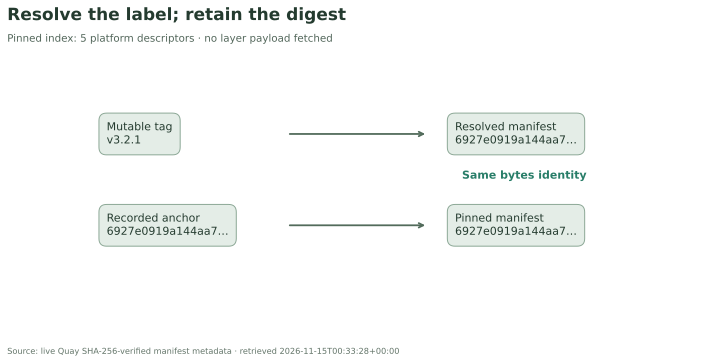

In [12]:
fig, ax = plt.subplots(figsize=(11, 5.3))
ax.axis("off")
r = comparison.iloc[0]
items = [
    (0.12, 0.72, "Mutable tag", str(r.current_tag)),
    (0.12, 0.25, "Recorded anchor", str(r.pinned_digest)[7:23] + "…"),
    (0.62, 0.72, "Resolved manifest", str(r.current_tag_digest)[7:23] + "…"),
    (0.62, 0.25, "Pinned manifest", str(r.pinned_digest)[7:23] + "…"),
]
for x, y, title, value in items:
    ax.text(
        x,
        y,
        title + "\n" + value,
        transform=ax.transAxes,
        ha="left",
        va="center",
        fontsize=11,
        bbox={"boxstyle": "round,pad=.7", "fc": "#E4EDE7", "ec": "#8CA896"},
    )
for y in [0.72, 0.25]:
    ax.annotate(
        "",
        xy=(0.58, y),
        xytext=(0.38, y),
        xycoords="axes fraction",
        arrowprops={"arrowstyle": "->", "lw": 1.8, "color": "#526B5B"},
    )
ax.text(
    0.63,
    0.49,
    "Same bytes identity" if r.same_manifest else "Different bytes identities",
    transform=ax.transAxes,
    color="#287D68" if r.same_manifest else "#A46F3E",
    weight="bold",
)
finish(
    fig,
    "Resolve the label; retain the digest",
    f"Pinned index: {r.pinned_platform_descriptors} platform descriptors · no layer payload fetched",
    f"Source: live Quay SHA-256-verified manifest metadata · retrieved {STARTED_UTC}",
    name="manifest-reference-chain",
)

### Verify identity without requiring a tag to stay fixed forever

Checks require the pinned manifest to equal the requested digest and verify unique
bounded query identities. They deliberately do not assert tag equality with the anchor:
a legitimate future tag update should remain an interpretable result. NULL provider
measures are retained, and no missing tag-page row is converted into a nonexistence claim.

In [13]:
%%sql checks <<
SELECT 'one configured container source' AS check_name,count(*)=1 AND min(source_id)='quay_public' AS passed FROM sources
UNION ALL SELECT 'anonymous source',bool_and(authentication='anonymous' AND NOT credential_configured) FROM sources
UNION ALL SELECT 'seven supported operations',count(*)=7 AND count(DISTINCT operation)=7 AND bool_and(supported) FROM capabilities
UNION ALL SELECT 'native readiness is not indexed completeness',count(*)=1 AND bool_and(ready AND search_mode='native') AND count(complete)=0 FROM source_status
UNION ALL SELECT 'bounded search identities',count(*)>0 AND count(*)<=8 AND count(*)=count(DISTINCT name) FROM discovered
UNION ALL SELECT 'explicit repository identity',count(*)=1 AND bool_and(name='prometheus/prometheus' AND source_id='quay_public') FROM repository
UNION ALL SELECT 'bounded unique tags',count(*)>0 AND count(*)<={{TAG_LIMIT}} AND count(*)=count(DISTINCT tag) FROM tag_page
UNION ALL SELECT 'all tag rows own the chosen repository',bool_and(name='prometheus/prometheus' AND source_id='quay_public') FROM tag_page
UNION ALL SELECT 'one resolved tag',count(*)=1 AND min(reference)='v3.2.1' AND regexp_full_match(min(digest),'sha256:[0-9a-f]{64}') FROM resolved_tag
UNION ALL SELECT 'immutable digest identity',count(*)=1 AND min(digest)='sha256:6927e0919a144aa7616fd0137d4816816d42f6b816de3af269ab065250859a62' FROM pinned_index
UNION ALL SELECT 'pinned platform descriptors exist',json_array_length(metadata,'$.manifests')>0 FROM pinned_index
UNION ALL SELECT 'comparison reports equality truthfully',count(*)=1 AND bool_and(same_manifest=(current_tag_digest=pinned_digest)) FROM comparison;

In [14]:
assert len(checks) == 12 and checks.passed.all()
display(checks)
_ = Path("artifacts/tag-audit.json").write_text(
    json.dumps(
        {
            "parameter": TAG_LIMIT,
            "inventory": inventory.to_dict("records"),
            "tags": tags.to_dict("records"),
            "search_names": search_names.to_dict("records"),
            "comparison": comparison.to_dict("records"),
            "checks": checks.to_dict("records"),
        },
        indent=2,
        default=str,
    )
    + "\n"
)
prose(
    f"All **{len(checks)} controls** pass. Registry discovery stays bounded, and the immutable anchor stays explicit. The result contains no payload download, execution or security verdict."
)

,check_name,passed
0,one configured container source,True
1,anonymous source,True
2,seven supported operations,True
3,native readiness is not indexed completeness,True
4,bounded search identities,True
5,explicit repository identity,True
6,bounded unique tags,True
7,all tag rows own the chosen repository,True
8,one resolved tag,True
9,immutable digest identity,True


All **12 controls** pass. Registry discovery stays bounded, and the immutable anchor stays explicit. The result contains no payload download, execution or security verdict.

### Experiment: request a longer tag page

Change **TAG_LIMIT from 8 to 16**. Compare returned labels and the budget marker. If
upstream ordering and contents are unchanged, the larger result retains the earlier
labels and adds more. The selected repository, tag and immutable digest stay fixed;
the reference comparison should remain the same unless the tag actually moved.
Retrieval timestamps change because this is a new live query. A longer page does not
make the tags a semantic version order or identify the best image. Restore 8 afterward.

In [15]:
assert connection.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
session.close()
public.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-software-packages](https://github.com/Query-farm/vgi-software-packages)